# 02 – Matching the market cycle

Does the market's mood when an IPO prices change how it trades? For each comparable we record the Nasdaq Composite's
return over the **3 months** and **12 months** before pricing. We then find the past IPOs whose market looked most like today's (nearest neighbours).

In [1]:
import sys, warnings; warnings.filterwarnings("ignore"); sys.path.insert(0, "../src")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, ipo
comps = ipo.load_comparables("../data/comparables.csv")
paths = pd.read_csv("../data/paths.csv", index_col=0)   # produced by notebook 01
ctx, now = ipo.market_context(comps)
ctx["day1"] = paths.iloc[0] - 100
ctx["stock_1y"] = paths.iloc[252] - 100 if len(paths) > 252 else np.nan
ctx["stock_1y_from_close"] = (paths.iloc[252] / paths.iloc[0] - 1) * 100
ctx["excess_1y"] = ctx.stock_1y - ctx.nasdaq_1y_after
print("Nasdaq today:", now.to_dict())
ctx.round(1)

Nasdaq today: {'nasdaq_3m_before': 6.1, 'nasdaq_12m_before': 11.9}


,nasdaq_3m_before,nasdaq_12m_before,nasdaq_1y_after,day1,stock_1y,stock_1y_from_close,excess_1y
ticker,,,,,,,
GOOGL,-4.1,3.3,17.4,18.0,229.4,179.0,212.0
V,-15.0,-7.7,-32.9,28.4,19.7,-6.7,52.6
GM,13.5,14.6,2.9,3.6,-34.0,-36.3,-36.9
META,-5.9,-1.3,24.6,0.6,-33.8,-34.2,-58.4
BABA,5.1,20.9,5.4,38.1,-6.0,-31.9,-11.4
SNAP,11.5,24.6,23.8,44.0,5.9,-26.4,-17.9
LYFT,17.4,9.4,0.6,8.7,-62.6,-65.6,-63.2
PINS,11.7,9.6,7.0,28.4,-8.3,-28.6,-15.3
ZM,11.7,9.6,7.0,72.2,313.9,140.3,306.9


## Hot market → bigger pop? Better year?

In [2]:
ctx[["nasdaq_3m_before", "nasdaq_12m_before"]].corrwith(ctx.day1).round(2).rename("corr with day-1 pop"), \
ctx[["nasdaq_3m_before", "nasdaq_12m_before"]].corrwith(ctx.stock_1y).round(2).rename("corr with 1y return")

(nasdaq_3m_before     0.4
 nasdaq_12m_before    0.3
 Name: corr with day-1 pop, dtype: float64,
 nasdaq_3m_before    -0.09
 nasdaq_12m_before    0.14
 Name: corr with 1y return, dtype: float64)

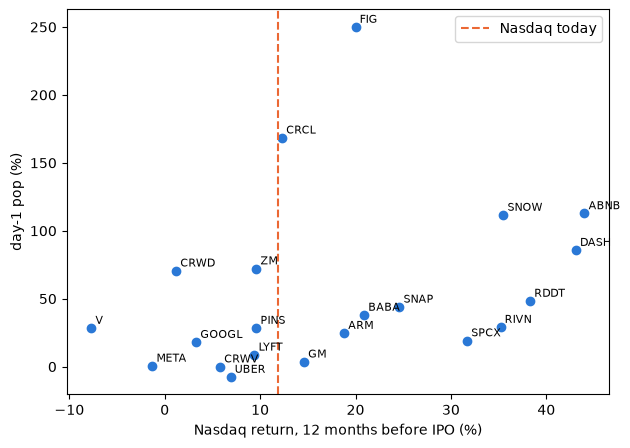

In [3]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(ctx.nasdaq_12m_before, ctx.day1, color="#2a78d6")
for t, r in ctx.iterrows():
    ax.annotate(t, (r.nasdaq_12m_before, r.day1), fontsize=8, xytext=(3, 3), textcoords="offset points")
ax.axvline(now.nasdaq_12m_before, color="#eb6834", ls="--", label="Nasdaq today")
ax.set(xlabel="Nasdaq return, 12 months before IPO (%)", ylabel="day-1 pop (%)"); ax.legend(); plt.show()

## Nearest neighbours: past IPOs priced into a market like today's

In [4]:
ctx["dist"] = np.hypot(ctx.nasdaq_3m_before - now.nasdaq_3m_before, ctx.nasdaq_12m_before - now.nasdaq_12m_before)
nn = ctx.drop("SPCX").nsmallest(7, "dist")
display(nn[["nasdaq_3m_before", "nasdaq_12m_before", "day1", "stock_1y", "stock_1y_from_close", "excess_1y"]].round(1))
nn[["day1", "stock_1y", "stock_1y_from_close", "excess_1y"]].median().round(1)

,nasdaq_3m_before,nasdaq_12m_before,day1,stock_1y,stock_1y_from_close,excess_1y
ticker,,,,,,
CRCL,4.0,12.3,168.5,166.2,-0.8,131.8
UBER,8.5,6.9,-7.6,-29.7,-23.9,-45.8
PINS,11.7,9.6,28.4,-8.3,-28.6,-15.3
ZM,11.7,9.6,72.2,313.9,140.3,306.9
GM,13.5,14.6,3.6,-34.0,-36.3,-36.9
ARM,2.2,18.8,24.7,171.4,117.6,145.1
BABA,5.1,20.9,38.1,-6.0,-31.9,-11.4


day1                   28.4
stock_1y               -6.0
stock_1y_from_close   -23.9
excess_1y             -11.4
dtype: float64

## Takeaways
- A hotter market goes with a **bigger first-day pop** (correlation about 0.3–0.4), but it says **almost nothing about the first year**.
- Today's Nasdaq (about +6% over 3 months, +12% over 12 months) is *moderate*. It looks less like the 2020–21 frenzy (Snowflake, Airbnb, DoorDash) and more like 2019 (Uber, Pinterest, Zoom) or 2025 (Circle).
- The 7 closest-market neighbours had a median day-1 pop of about +28%, a 1-year return of about −6% from the offer price, and about −24% from the first-day close. With only 7 IPOs the spread is huge (Zoom +140%, Alibaba −32%), so this is a weak signal, not a forecast.
- SpaceX is excluded from the neighbours because it doesn't have a full year of data yet.